In [1]:
import sys
sys.path.append('../../src')

In [2]:
import pandas as pd
import numpy
from energiapy.components.temporal_scale import TemporalScale
from energiapy.components.resource import Resource, VaryingResource, Scope
from energiapy.components.process import Process, VaryingProcess
from energiapy.components.material import Material
from energiapy.components.location import Location
from energiapy.components.network import Network
from energiapy.components.scenario import Scenario
from energiapy.components.transport import Transport
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.plot import plot_results, plot_scenario
from energiapy.plot.plot_results import CostY, CostX
from energiapy.model.solve import solve
from itertools import product
from energiapy.components.result import Result
from itertools import product
from matplotlib import rc
import matplotlib.pyplot as plt
from energiapy.model.solve import solve
from energiapy.plot.plot_results import CostY, CostX
from energiapy.components.location import Location
from energiapy.plot import plot_results, plot_scenario
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.model.bounds import CapacityBounds
from energiapy.utils.data_utils import get_data, make_henry_price_df, remove_outliers, load_results
from energiapy.conversion.photovoltaic import solar_power_output
from energiapy.conversion.windmill import wind_power_output
from energiapy.model.constraints.integer_cuts import constraint_block_integer_cut, constraint_block_integer_cut_min
from scipy import stats

In [3]:
# To solve the scheduling level problem for the motivating example of 3 forms of LNG production with varying GWP (resets every year), varying ERCOT power prices & NG prices (fluctuates every hour for the next 5 years)
# For optimal cost vs emission scenario (and varying weights for emission reduction , eg, for 10% reduction in emission, what is the best case scenario)

In [4]:
horizon = 1
scales = TemporalScale(discretization_list=[5,4,91])

#1,24

In [5]:
bigM = 10**8
smallM = 0.001

In [6]:
import pandas as pd

# Read the Excel file into a DataFrame
elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/Complete_ERCOT_Prices - 5 year_Daily.csv')
#elec_price_df = elec_price_df[:365].reset_index(drop = True)
elec_price_df = elec_price_df[:1820].reset_index(drop = True)
elec_price_df

# Increment index by 1 (optional, depending on what you want to do)
# elec_price_df.index = elec_price_df.index + 1

# Display DataFrame
# print(elec_price_df)

# Get the maximum price from the first column


,Settlement Point Price
0,14.70
1,18.45
2,17.73
3,13.60
4,16.14
...,...
1815,16.41
1816,19.66
1817,21.96
1818,14.41


In [7]:
import pandas as pd

# Read the Excel file into a DataFrame
LNG_demand_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/CorpusChristi_LNG.csv')
LNG_demand_df = LNG_demand_df[['LNG FQ']]
LNG_demand_df = LNG_demand_df[:20].reset_index(drop = True)
LNG_demand_df 
#LNG_demand_df


,LNG FQ
0,1782564.524
1,1875872.854
2,1463448.206
3,1402097.293
4,1859535.239
5,1957717.097
6,1557430.210
7,1475460.199
8,1960934.388
9,2061632.989


In [8]:
# elec_price_df = pd.read_excel(r'C:\Users\marcopdsousa\Documents\energiapy\AICHE\AICHE 2025 Data\Complete_ERCOT_Prices_RepresentativeDay.xlsx')
# elec_price_df.index


In [9]:
# elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Hourly Prices Belgium.csv')
# #elec_price_df = elec_price_df[elec_price_df['SettlementPoint'] == 'HB_HOUSTON']
# elec_price_df = elec_price_df[['Price (EUR/MWhe)']].reset_index(drop = True)
# elec_price_df = elec_price_df[:8760]
# elec_price_df['Price (EUR/MWhe)'] = elec_price_df['Price (EUR/MWhe)'].clip(lower=0)
# elec_price_df

In [10]:
# elec_price_df

In [11]:
# Formula verified

#for index in elec_price_df.index:
    #if index <= 20:
        #GWP_value = 112.23
    #elif index <= 70:
        #GWP_value = 99.99
    #elif index <= 72:
        #GWP_value = 92.84
    #else:
        #GWP_value = 83.82
    
    #print(f"Index: {index}, GWP_value: {GWP_value}")  # To check the values dynamically


In [12]:
# for index in elec_price_df.index:
#     if index <= 365:
#         GWP_value = 112.23
#     elif index >365 and index<= 730:
#         GWP_value = ((99.99*(index - 365))+(112.23*365))/(index)
#     elif index >730 and index<= 1095:
#         GWP_value = ((92.84*(index - 730))+(99.99*365)+(112.23*365))/index
#     elif index >1095 and index<= 1460:
#         GWP_value = ((87.76*(index - 1095))+(99.99*365)+(112.23*365)+(92.84*730))/index
#     else:
#         GWP_value= (83.82*((index - 1460))+(87.76*365)+(99.99*365)+(112.23*365)+(92.84*730))/index
#         # for 5 years

## True Fuel mix GWP

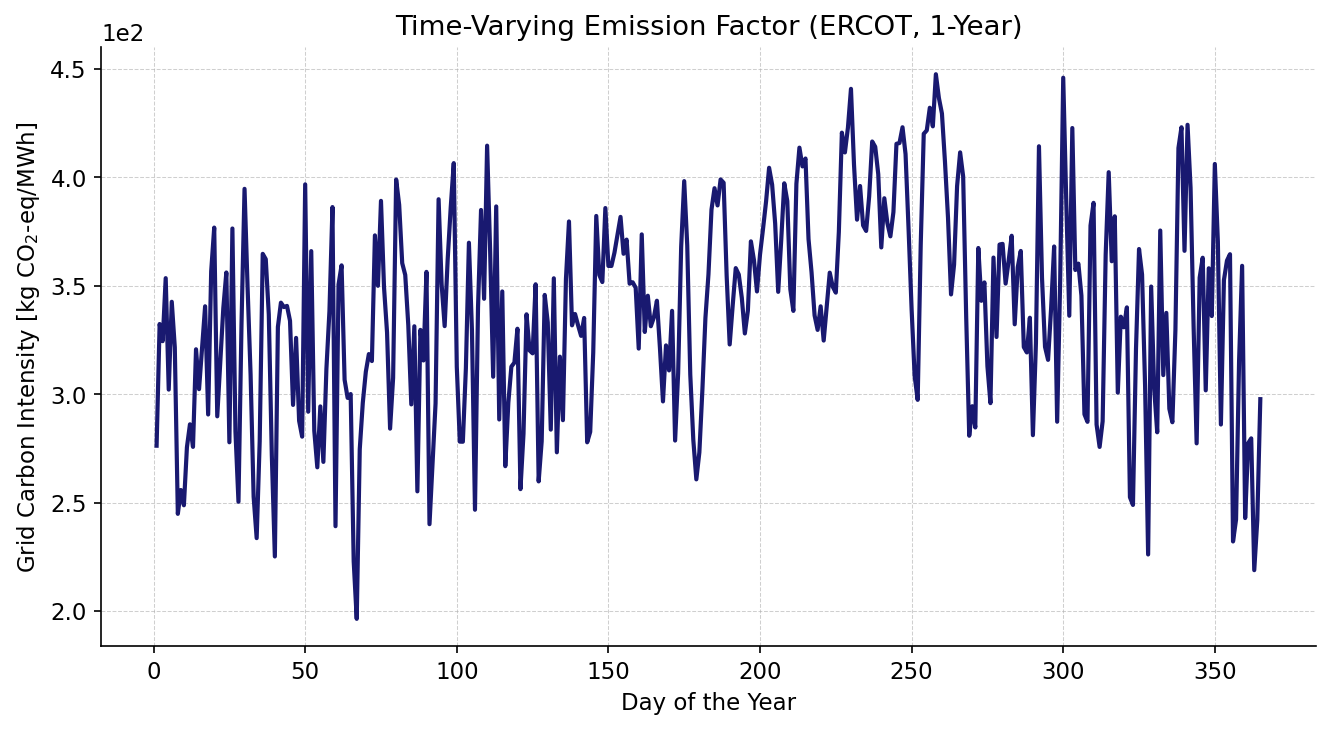

In [89]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd

# # --- Load and prepare data ---
# TVEF_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
# TVEF_df = TVEF_df[['GWP']].iloc[:365].reset_index(drop=True)

# days = np.arange(1, len(TVEF_df) + 1)
# values = TVEF_df['GWP']

# # --- Plot ---
# plt.figure(figsize=(9, 5), dpi=150)
# plt.plot(days, values, color='midnightblue', linewidth=2)
# plt.xlabel('Day of the Year')
# plt.ylabel('Grid Carbon Intensity [kg CO$_2$-eq/MWh]')
# plt.title('Time-Varying Emission Factor (ERCOT, 1-Year)')
# plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
# plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
# plt.tight_layout()
# plt.show()


In [14]:
#The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
TVEF_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
# NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
TVEF_df = TVEF_df[['GWP']]
TVEF_df = TVEF_df[:1820].reset_index(drop = True)
TVEF_df

,GWP
0,276.211933
1,332.332728
2,324.429326
3,353.487385
4,302.086112
...,...
1815,315.482312
1816,315.482312
1817,315.482312
1818,315.482312


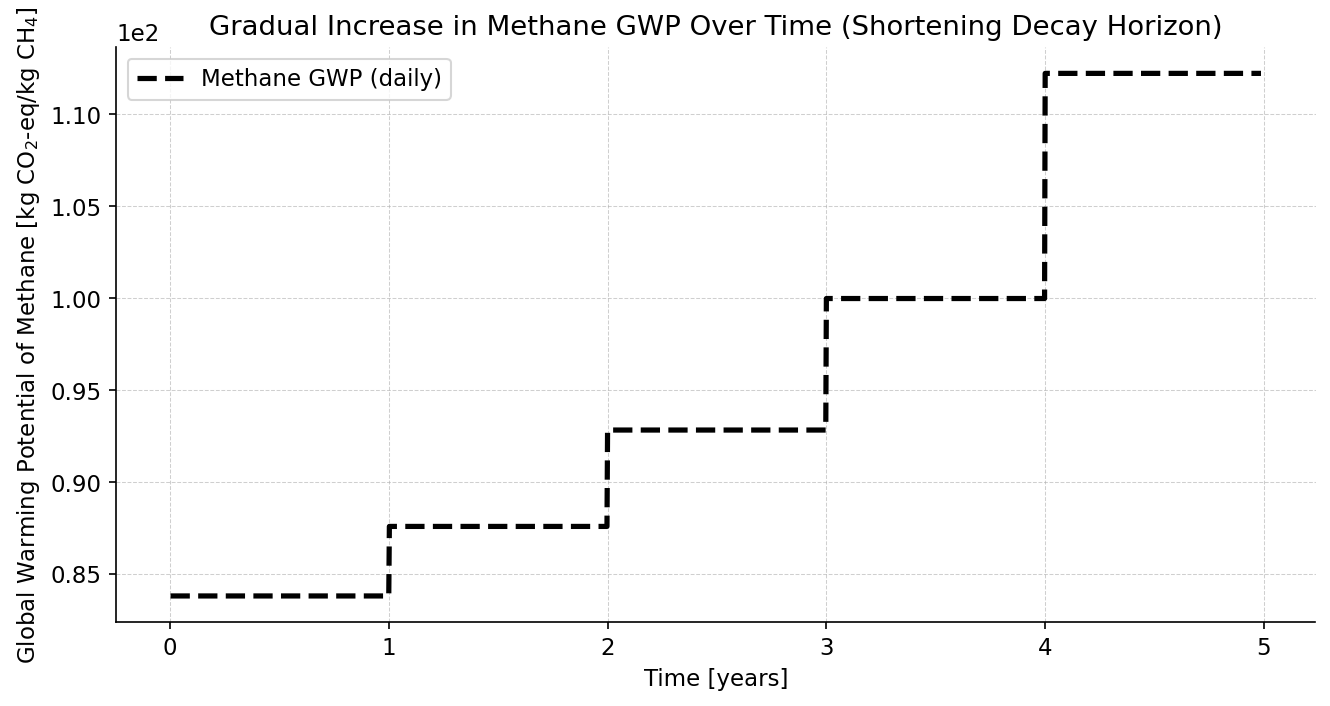

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Load and prepare data ---
GWP_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
GWP_df = GWP_df[['Methane']].iloc[:1820].reset_index(drop=True)

# Time axis: 1820 days ≈ 5 years
days = np.arange(1, len(GWP_df) + 1)
years = days / 365  # convert to years for better interpretability

# --- Plot ---
plt.figure(figsize=(9, 5), dpi=150)
plt.plot(years, GWP_df['Methane'], color='black', linewidth=2.5, label='Methane GWP (daily)', linestyle="--")
plt.xlabel('Time [years]')
plt.ylabel('Global Warming Potential of Methane [kg CO$_2$-eq/kg CH$_4$]')
plt.title('Gradual Increase in Methane GWP Over Time (Shortening Decay Horizon)')

# # Optional: smooth trend (7-day rolling)
# rolling = GWP_df['Methane'].rolling(window=30, center=True, min_periods=1).mean()
# plt.plot(years, rolling, color='crimson', linestyle='--', linewidth=2, label='30-day average')

# Grid and formatting
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
#The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
GWP_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
# NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
GWP_df = GWP_df[['Methane']]
GWP_df = GWP_df[:1820].reset_index(drop = True)
GWP_df

,Methane
0,83.82
1,83.82
2,83.82
3,83.82
4,83.82
...,...
1815,112.23
1816,112.23
1817,112.23
1818,112.23


## Test GWP Mix


In [16]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# GWP_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Carbon Intensity Belgium.csv')
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# GWP_df = GWP_df[['Carbon intensity Full']]
# GWP_df = GWP_df[:8760].reset_index(drop = True)
# GWP_df

In [17]:
TVEF_value = TVEF_df.max()[0]
GWP_value = GWP_df.max()[0]
elec_price = elec_price_df.max()[0]

C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_3000\1306193089.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  TVEF_value = TVEF_df.max()[0]
C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_3000\1306193089.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  GWP_value = GWP_df.max()[0]
C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_3000\1306193089.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  elec_price = elec_pri

In [18]:
# Outputs

CO2 = Resource(name='CO2 Vented from the process', basis='kg/hr',
               label='Carbon dioxide vented from the process', block='Resource', gwp = 1, sell=True, scope = Scope.ONE)

Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               label='Methane from the process', block='Resource', cons_max = bigM, gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP], sell=True, scope = Scope.ONE)

#gwp = 112.23
#cons_max = bigM, gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP],

MethaneD = Resource(name='Dynamic Methane emission', basis='kg', label='Methane emitted')

NGL = Resource(name='Natural Gas Liquids_in_extraction', basis='kg/hr', label='Natural Gas Liquids_in_extraction', block='Resource', sell=True)

ProducedWater = Resource(name='H2O vented from the process',
               basis='kg/hr', sell=True, label='Water vented from the process', block='Resource')

LNG = Resource(name='LNG', demand = True, basis='kg/hr', label='LNG', block='Resource')

#, varying=[VaryingResource.DETERMINISTIC_DEMAND]

Boil_off_LNG = Resource(name='Boil_off_LNG', sell=True, basis='kg/hr', label='Boil_off_LNG', block='Resource')

Heat_Energy = Resource(name='Heat_Energy', basis='MW', label='Heat_Energy', sell=True, block='Resource')

#Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               #label='Methane from the process', block='Resource', gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP], sell=True, scope = Scope.ONE)

# Inputs

Power = Resource(name='Power', basis='MW', label='Power generated')

GridPower = Resource(name='GridPower', basis='MW',
                     cons_max=bigM, label='Power bought', gwp= TVEF_value, price =elec_price ,varying = [VaryingResource.DETERMINISTIC_PRICE, VaryingResource.DETERMINISTIC_GWP], scope = Scope.TWO)
# Grid Power GWP from average value of time-varying GWP

ResourceWater = Resource(name='H2O',
               basis='kg/hr', cons_max=bigM, label='Water', price = 0.002, block='Resource')

Proppant_Additive = Resource(name='Proppant_Additive', basis='kg/hr', label='Proppant_Additive', block='Resource', price= 0.975, cons_max=bigM)
# Reference Link: https://www.maximizemarketresearch.com/market-report/global-proppant-market/14899/?utm_source=chatgpt.com

Diesel = Resource(name='Diesel', basis='kg/hr', label='Diesel', block='Resource', price= 0.98, cons_max=bigM)
# Reference Link: https://businessanalytiq.com/procurementanalytics/index/diesel-price-index/

Cooling_Water_In_Liquifaction = Resource(name='Cooling_Water_In_Liquifaction', basis='kg/hr', label='Cooling_Water_In_Liquifaction', block='Resource', cons_max=bigM, price= 0.0572)
# Reference link: https://www.intratec.us/products/industry-economics-worldwide/utility/cooling-water-united-states

LNG =  Resource(name='LNG', demand=True, basis='kg/hr', label='LNG', block='Resource')

Glycol = Resource(name='Glycol', basis='kg/hr', label='Glycol', block='Resource', cons_max=bigM, price= 0.052)
# Reference link: https://businessanalytiq.com/procurementanalytics/index/ethylene-glycol-price-index/

MDEA = Resource(name='MDEA', basis='kg/hr', label='MDEA', block='Resource', cons_max=bigM)


DP1 = Resource(name='DP1', basis='kg/hr', cons_max= 988, price=4, 
               label='DP1', block='Resource') #5% deviation
DP2 = Resource(name='DP2', basis='kg/hr', cons_max= 988, price=9, 
               label='DP2', block='Resource') #10% deviation 1976
DP3 = Resource(name='DP3', basis='kg/hr', cons_max= 988, price= 15, 
               label='DP3', block='Resource') #15% deviation 2965
DP4 = Resource(name='DP4', basis='kg/hr', cons_max= 988, price= 21, 
               label='DP4', block='Resource') #20% deviation 3953
DP5 = Resource(name='DP5', basis='kg/hr', cons_max= 988, price= 29, 
               label='DP5', block='Resource') #25% deviation 4942
DP6 = Resource(name='DP6', basis='kg/hr', cons_max= 988, price= 37, 
               label='DP6', block='Resource') #30% deviation 5930

In [85]:
988/0.05

5930/0.3

19766.666666666668

In [19]:
19768.78904109589*0.3



5930.636712328766

In [20]:
print(elec_price_df.shape[0])

1820


In [21]:
# FU: 1 kg/hr of LNG
# 3 methane producing processes

Grid = Process(name='Grid', conversion={GridPower: -1, Power: 1}, prod_min=smallM, prod_max=bigM, label='Grid', basis='MW')

MDGWP = Process(name='MDGWP', conversion={Methane: -1, MethaneD: 1}, prod_min=smallM, prod_max=bigM, label='MDGWP', basis='kg')

Conventional_NG = Process(name='Conventional_NG', conversion={Boil_off_LNG: 0.01, Power: -0.0028, ResourceWater: -0.5, Diesel: -0.000741382, Glycol: -0.000818111, MDEA: -0.012391658, Cooling_Water_In_Liquifaction: -1.75,
                                                              MethaneD: -0.00395, CO2: 0.966504505 , NGL: 0.3, Heat_Energy: 0.02, ProducedWater: 0.912, LNG: 1}, capex=0.17, fopex=1.5, vopex=1.5, prod_min=0.1, prod_max=bigM, label='Conventional LNG', basis='kg/hr')  

ShaleGas = Process(name='ShaleGas', conversion={Boil_off_LNG: 0.01, Power: -0.003, ResourceWater: -0.92, Diesel: -0.002041766, Glycol: -0.01875, MDEA: -0.284, Cooling_Water_In_Liquifaction: -2.75,
                                                              MethaneD: -0.00895, CO2: 2.1, NGL: 1.9, Heat_Energy: 0.074, ProducedWater: 2.2205, LNG: 1}, capex=0.19, fopex=0.6, vopex=0.6, prod_min=0.1, prod_max=bigM, label='ShaleGas', basis='kg/hr')

Coalbed = Process(name='Coalbed', conversion={Boil_off_LNG: 0.01, Power: -0.01, Diesel: -0.075, Glycol: -0.026539527, MDEA: -0.401985372, Cooling_Water_In_Liquifaction: -3.25,
                                                              MethaneD: -0.811, CO2: 5.823126126, NGL: 0.062761905, Heat_Energy: 0.002, ProducedWater: 6.2755, LNG: 1}, capex=0.205, fopex=2.24, vopex=1.17, prod_min=0.1, prod_max=bigM, label='CoalBed', basis='kg/hr')

D1 = Process(name="D1", conversion={DP1:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D1', basis='kg/hr')
D2 = Process(name="D2", conversion={DP2:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D2', basis='kg/hr')
D3 = Process(name="D3", conversion={DP3:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D3', basis='kg/hr')
D4 = Process(name="D4", conversion={DP4:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D4', basis='kg/hr')
D5 = Process(name="D5", conversion={DP5:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D5', basis='kg/hr')
D6 = Process(name="D6", conversion={DP6:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D6', basis='kg/hr')
# capacity needed? No

# https://marcelluscoalition.org/wp-content/uploads/2012/07/The-Arithmetic-of-Shale-Gas.pdf

# https://shareholdersunite.com/the-ioc-files-useful-background-material/the-economics-of-lng/

In [22]:
process_set = {Grid, Conventional_NG, ShaleGas, Coalbed, MDGWP, D1, D2, D3, D4, D5, D6}

In [23]:
# network scale level is 2, due to indexing issues. However, this shouldn't change the final output as capex is smallM. Fopex will be mentiond in hourly level
#{Methane:GWP_value, GridPower: GWP_df}

houston = Location(name='Houston', processes=process_set,  price_factor={GridPower: elec_price_df}, gwp_factor= {GridPower: TVEF_df, Methane: GWP_df}, demand_factor= {LNG: LNG_demand_df}, expenditure_scale_level=0,
                   scales=scales, label='Houston', demand_scale_level=1, price_scale_level=2, gwp_scale_level = 2)


In [24]:

scenario = Scenario(name='scenario_full', network=houston, scales=scales,  demand_scale_level=1, expenditure_scale_level=0,
                    purchase_scale_level = 2, scheduling_scale_level=2, network_scale_level=0, gwp_scale_level = 2, 
                    label='full_case', demand={houston: {LNG:2265757}})

#, demand={houston: {LNG:1977000}}

In [83]:
2265757/30

75525.23333333334

In [84]:
75525.23333333334*0.05

3776.261666666667

In [25]:
7215608*0.05

360780.4

In [26]:
print("Contents of scenario.gwp_dict:", Location.gwp_factor)
#code not reading demand or gwp factor

Contents of scenario.gwp_dict: None


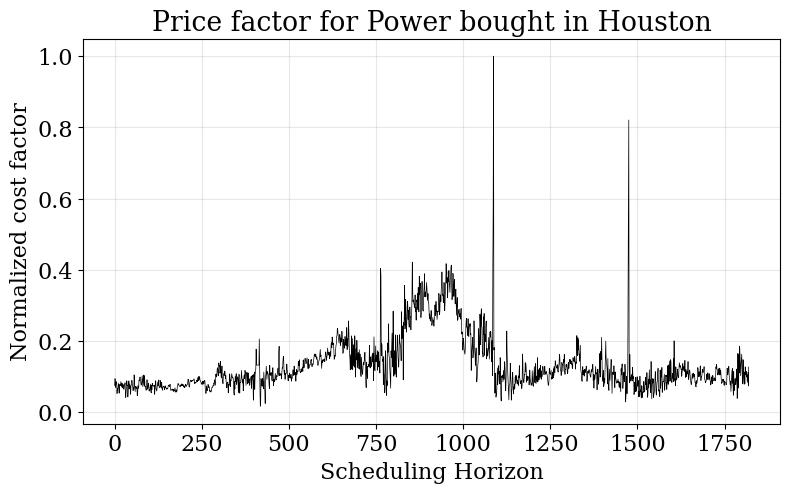

In [27]:
plot_scenario.price_factor(scenario=scenario, location=houston, resource=GridPower, fig_size=(9, 5), color='black')

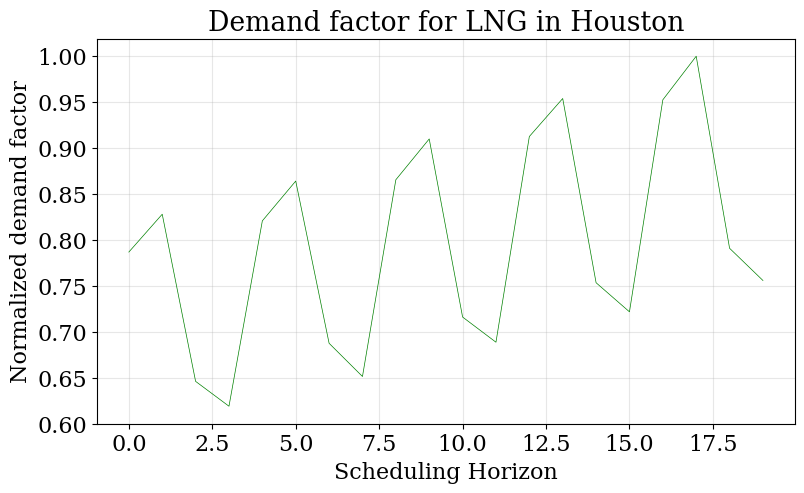

In [28]:
plot_scenario.demand_factor(
     scenario=scenario, location=houston, resource=LNG, fig_size=(9, 5), color='green')

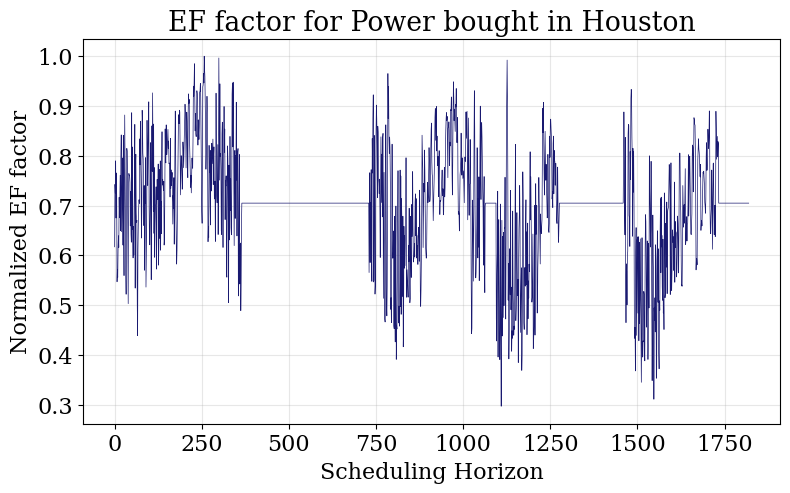

In [51]:
plot_scenario.gwp_factor(
    scenario=scenario, location=houston, resource=GridPower, fig_size=(9, 5), color='midnightblue')

In [29]:
#, Constraints.MODE

milp_cost = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost


## Capacity constrained ramping based on Nameplate Capacity

In [30]:
# from pyomo.environ import ConstraintList

# # Loop of how this code runs
# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate   *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]
# # *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]

# milp_cost.cons1 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons1.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.1* milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])

# #Constraint 2: Ramp down

# milp_cost.cons2 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons2.add(expr = milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.1*milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])


# # Loop of how this code runs
# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons3 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons3.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.2* milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

# #Constraint 2: Ramp down

# milp_cost.cons4 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons4.add(expr = milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.2*milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

# # Loop of how this code runs
# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons5 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons5.add(expr = milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.15* milp_cost.Cap_P['Houston', 'Coalbed', i[0]])

# #Constraint 2: Ramp down

# milp_cost.cons6 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0,0):
#         milp_cost.cons6.add(expr = milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.15*milp_cost.Cap_P['Houston', 'Coalbed', i[0]])


# milp_cost.cons7 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons7.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] >= 0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

# #0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

# milp_cost.cons8 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons8.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] >= 0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]])

# #0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

# milp_cost.cons9 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons9.add(expr = milp_cost.P['Houston', 'Coalbed', *i] >= 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]])

# # 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]]

In [31]:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate   *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]
# *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]

milp_cost.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons1.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])

#Constraint 2: Ramp down

milp_cost.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons2.add(expr = milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.10*milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])


# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons3.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

#Constraint 2: Ramp down

milp_cost.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons4.add(expr = milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.2*milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons5.add(expr = milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* milp_cost.Cap_P['Houston', 'Coalbed', i[0]])

#Constraint 2: Ramp down

milp_cost.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons6.add(expr = milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.15*milp_cost.Cap_P['Houston', 'Coalbed', i[0]])


milp_cost.cons7 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons7.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] >= 0.5*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

#0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

milp_cost.cons8 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons8.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] >= 0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]])

#0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

milp_cost.cons9 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons9.add(expr = milp_cost.P['Houston', 'Coalbed', *i] >= 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]])

# 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]]

In [32]:
# from pyomo.environ import Var, Binary, ConstraintList

# def add_no_immediate_reversal(m, loc, proc, idx, eps=1e-6, buffer_steps=1):
#     """
#     m    : Pyomo model
#     loc  : e.g., 'Houston'
#     proc : e.g., 'Conventional_NG'
#     idx  : ordered list of time indices, e.g., list(scales.scale_iter(1))
#     eps  : tiny band around zero treated as 'flat'
#     buffer_steps : require at least this many steps before direction can flip
#                    e.g., 1 means you cannot go up at t and down at t+1
#     """

#     # Aux ramp var Δ_t = P_t - P_{t-1}  (for t >= 1)
#     m.DELTA = getattr(m, f"DELTA_{proc}", None) or Var(range(1, len(idx)))
#     setattr(m, f"DELTA_{proc}", m.DELTA)

#     # Direction binaries (exactly one active): up, down, flat
#     m.UP   = getattr(m, f"UP_{proc}", None)   or Var(range(1, len(idx)), domain=Binary)
#     m.DOWN = getattr(m, f"DOWN_{proc}", None) or Var(range(1, len(idx)), domain=Binary)
#     m.FLAT = getattr(m, f"FLAT_{proc}", None) or Var(range(1, len(idx)), domain=Binary)
#     setattr(m, f"UP_{proc}", m.UP)
#     setattr(m, f"DOWN_{proc}", m.DOWN)
#     setattr(m, f"FLAT_{proc}", m.FLAT)

#     # Constraints
#     c = ConstraintList()
#     setattr(m, f"cons_no_rev_{proc}", c)

#     # Big-M for the ramp (Δ bounds). Use capacity as a safe M.
#     # If your Cap_P varies by the first index (year), pull that per t.
#     for t in range(1, len(idx)):
#         i_t   = idx[t]
#         i_tm1 = idx[t-1]
#         cap_t = m.Cap_P[loc, proc, i_t[0]]     # adjust if your cap index differs
#         M     = cap_t

#         # Define Δ_t
#         c.add(expr = m.DELTA[t] == m.P[loc, proc, *i_t] - m.P[loc, proc, *i_tm1])

#         # One-hot: exactly one of {UP, DOWN, FLAT} is 1
#         c.add(expr = m.UP[t] + m.DOWN[t] + m.FLAT[t] == 1)

#         # Bind Δ_t to the chosen direction (with small epsilon for 'flat')
#         # UP:  Δ_t ≥  eps, Δ_t ≤  M
#         c.add(expr = m.DELTA[t] >=  eps - M*(1 - m.UP[t]))
#         c.add(expr = m.DELTA[t] <=      M*(    m.UP[t]))

#         # DOWN: Δ_t ≤ -eps, Δ_t ≥ -M
#         c.add(expr = m.DELTA[t] <= -eps + M*(1 - m.DOWN[t]))
#         c.add(expr = m.DELTA[t] >=     - M*(    m.DOWN[t]))

#         # FLAT: |Δ_t| ≤ eps
#         c.add(expr = m.DELTA[t] <=  eps + M*(1 - m.FLAT[t]))
#         c.add(expr = m.DELTA[t] >= -eps - M*(1 - m.FLAT[t]))

#     # No immediate reversal:
#     #   forbid UP at t and DOWN at t+1 (and vice-versa).
#     # If buffer_steps=1, this enforces at least a flat or continued same-direction step in between.
#     for t in range(1, len(idx) - 0 - buffer_steps):
#         # up then down within the buffer window is forbidden
#         c.add(expr = m.UP[t] + sum(m.DOWN[t+k] for k in range(1, buffer_steps+1)) <= 1)
#         # down then up within the buffer window is forbidden
#         c.add(expr = m.DOWN[t] + sum(m.UP[t+k] for k in range(1, buffer_steps+1)) <= 1)


## Ramping Constraints - Presently linked to production rate on previous timestep

In [33]:
# from pyomo.environ import ConstraintList

# # Fraction of capacity allowed for "acceleration" (change in ramp)
# accel_frac = 0.05  # try 0.02–0.10

# idx = list(scales.scale_iter(1))  # ordered list of time indices like (year, day) or (year, day, hour)

# # -------- Conventional NG --------
# milp_cost.cons_acc_ng_pos = ConstraintList()
# milp_cost.cons_acc_ng_neg = ConstraintList()

# for t in range(2, len(idx)):
#     i   = idx[t]
#     i_1 = idx[t-1]
#     i_2 = idx[t-2]
#     cap = milp_cost.Cap_P['Houston', 'Conventional_NG', i[0]]
#     A   = accel_frac * cap
#     # second difference: P_t - 2*P_{t-1} + P_{t-2}
#     sd  = (milp_cost.P['Houston','Conventional_NG', *i]
#            - 2*milp_cost.P['Houston','Conventional_NG', *i_1]
#            +   milp_cost.P['Houston','Conventional_NG', *i_2])
#     milp_cost.cons_acc_ng_pos.add(expr =  sd <= A)
#     milp_cost.cons_acc_ng_neg.add(expr = -sd <= A)

# # -------- Shale Gas --------
# milp_cost.cons_acc_sh_pos = ConstraintList()
# milp_cost.cons_acc_sh_neg = ConstraintList()

# for t in range(2, len(idx)):
#     i   = idx[t]
#     i_1 = idx[t-1]
#     i_2 = idx[t-2]
#     cap = milp_cost.Cap_P['Houston', 'ShaleGas', i[0]]
#     A   = accel_frac * cap
#     sd  = (milp_cost.P['Houston','ShaleGas', *i]
#            - 2*milp_cost.P['Houston','ShaleGas', *i_1]
#            +   milp_cost.P['Houston','ShaleGas', *i_2])
#     milp_cost.cons_acc_sh_pos.add(expr =  sd <= A)
#     milp_cost.cons_acc_sh_neg.add(expr = -sd <= A)

# # -------- Coalbed --------
# milp_cost.cons_acc_cb_pos = ConstraintList()
# milp_cost.cons_acc_cb_neg = ConstraintList()

# for t in range(2, len(idx)):
#     i   = idx[t]
#     i_1 = idx[t-1]
#     i_2 = idx[t-2]
#     cap = milp_cost.Cap_P['Houston', 'Coalbed', i[0]]
#     A   = accel_frac * cap
#     sd  = (milp_cost.P['Houston','Coalbed', *i]
#            - 2*milp_cost.P['Houston','Coalbed', *i_1]
#            +   milp_cost.P['Houston','Coalbed', *i_2])
#     milp_cost.cons_acc_cb_pos.add(expr =  sd <= A)
#     milp_cost.cons_acc_cb_neg.add(expr = -sd <= A)


# milp_cost.cons7 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons7.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] >= 0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

# #0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

# milp_cost.cons8 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons8.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] >= 0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]])

# #0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

# milp_cost.cons9 = ConstraintList()
# for i in scales.scale_iter(1):
#     #if i != (0,0):
#     milp_cost.cons9.add(expr = milp_cost.P['Houston', 'Coalbed', *i] >= 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]])

In [34]:
results_cost = solve(scenario=scenario, instance=milp_cost,
                     solver='gurobi', name=f"res_cost", print_solversteps=True, saveformat = '.pkl')

Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 210199 rows, 1131306 columns and 707677 nonzeros
Model fingerprint: 0x81493b78
Variable types: 1131251 continuous, 55 integer (55 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 168275 rows and 1109386 columns
Presolve time: 0.32s
Presolved: 41924 rows, 21920 columns, 118382 nonzeros
Variable types: 21865 continuous, 55 integer (25 binary)
Performing another presolve...
Presolve removed 20040 rows and 16311 columns
Presolve time: 1.37s

Root relaxation: objective 3.020089e+07, 3057 iterat

In [58]:
results_cost.output['objective']

30200894.23746552

In [71]:
#3073157.7669820026/3650000
#22497350.818022832/36078038.04
#3047005.0671211183

#30106159.97596918/36078038.04
#27402349.391043473/36078038.04
30200894.23746552/36078038.04

0.8370991295031497

In [37]:
1.35*3650000



4927500.0

In [38]:
5119027.431653369/730000

7.012366344730642

In [39]:
results_cost.output['X_P']

{('Houston', 'Coalbed', 0): -0.0,
 ('Houston', 'Coalbed', 1): -0.0,
 ('Houston', 'Coalbed', 2): -0.0,
 ('Houston', 'Coalbed', 3): -0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): -0.0,
 ('Houston', 'Conventional_NG', 1): -0.0,
 ('Houston', 'Conventional_NG', 2): -0.0,
 ('Houston', 'Conventional_NG', 3): -0.0,
 ('Houston', 'Conventional_NG', 4): -0.0,
 ('Houston', 'D1', 0): 1.0,
 ('Houston', 'D1', 1): 1.0,
 ('Houston', 'D1', 2): 1.0,
 ('Houston', 'D1', 3): 1.0,
 ('Houston', 'D1', 4): 1.0,
 ('Houston', 'D2', 0): 1.0,
 ('Houston', 'D2', 1): 1.0,
 ('Houston', 'D2', 2): 1.0,
 ('Houston', 'D2', 3): 1.0,
 ('Houston', 'D2', 4): 1.0,
 ('Houston', 'D3', 0): 1.0,
 ('Houston', 'D3', 1): 1.0,
 ('Houston', 'D3', 2): 1.0,
 ('Houston', 'D3', 3): 1.0,
 ('Houston', 'D3', 4): 1.0,
 ('Houston', 'D4', 0): 1.0,
 ('Houston', 'D4', 1): 1.0,
 ('Houston', 'D4', 2): 1.0,
 ('Houston', 'D4', 3): 1.0,
 ('Houston', 'D4', 4): 1.0,
 ('Houston', 'D5', 0): 1.0,
 ('Houston', 'D5', 1): 1.0,
 ('Ho

In [40]:
results_cost.output['global_warming_potential_location']

{('Houston', 0): 139938184.01091775,
 ('Houston', 1): 139938184.01091775,
 ('Houston', 2): 139938184.01091775,
 ('Houston', 3): 139938184.01091775,
 ('Houston', 4): 139938184.01091775}

In [41]:
results_cost.output['global_warming_potential_network']

{0: 139938184.01091775,
 1: 139938184.01091775,
 2: 139938184.01091775,
 3: 139938184.01091775,
 4: 139938184.01091775}

In [109]:
results_cost.output['global_warming_potential_resource']

{('Houston', 'Boil_off_LNG', 0, 0, 0): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 1): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 2): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 3): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 4): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 5): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 6): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 7): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 8): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 9): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 10): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 11): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 12): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 13): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 14): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 15): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 16): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 17): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 18): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 19): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 20): 0.0,
 ('Houston', 'Boil_off_LNG', 0, 0, 21): 0.0,
 ('Houston', 'Boil_o

In [ ]:
data = results_cost.output['global_warming_potential_resource']
df = pd.DataFrame(data,index=[0])
df = df.T
# Export the DataFrame to an Excel file
df.to_excel('C:\\Users\\marcopdsousa\\Desktop\\AICHE 2025\\AICHE DGWP TVEF Emission Breakdown.xlsx', index=True)

In [97]:
139938184.01091775*4/36078038

15.51505478329146

In [67]:
3.878763695822865-3.878763695822865*0.05

3.6848255110317214

In [42]:
results_cost.output['Cap_P']

{('Houston', 'Coalbed', 0): 0.0,
 ('Houston', 'Coalbed', 1): 0.0,
 ('Houston', 'Coalbed', 2): 0.0,
 ('Houston', 'Coalbed', 3): 0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): 0.0,
 ('Houston', 'Conventional_NG', 1): 0.0,
 ('Houston', 'Conventional_NG', 2): 0.0,
 ('Houston', 'Conventional_NG', 3): 0.0,
 ('Houston', 'Conventional_NG', 4): 0.0,
 ('Houston', 'D1', 0): 100000000.0,
 ('Houston', 'D1', 1): 100000000.0,
 ('Houston', 'D1', 2): 100000000.0,
 ('Houston', 'D1', 3): 100000000.0,
 ('Houston', 'D1', 4): 100000000.0,
 ('Houston', 'D2', 0): 100000000.0,
 ('Houston', 'D2', 1): 100000000.0,
 ('Houston', 'D2', 2): 100000000.0,
 ('Houston', 'D2', 3): 100000000.0,
 ('Houston', 'D2', 4): 100000000.0,
 ('Houston', 'D3', 0): 100000000.0,
 ('Houston', 'D3', 1): 100000000.0,
 ('Houston', 'D3', 2): 100000000.0,
 ('Houston', 'D3', 3): 100000000.0,
 ('Houston', 'D3', 4): 100000000.0,
 ('Houston', 'D4', 0): 100000000.0,
 ('Houston', 'D4', 1): 100000000.0,
 ('Houston', 'D4',

[13584.752454478039, 8644.84247103148, 8644.84247103148, 13584.752454478039, 9879.81996689312, 14819.729950339679, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 14819.729950339679, 19759.63993378624, 24699.549917232798, 19759.63993378624, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24451.941309597118, 19512.031326150558, 14572.121342703998, 9879.8199668931

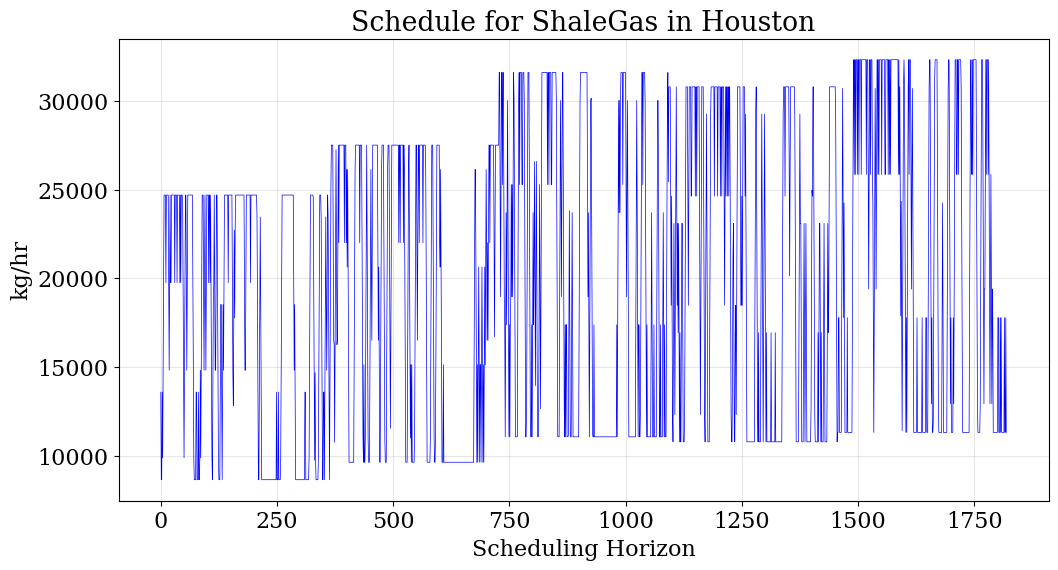

In [43]:
plot_results.schedule(results = results_cost, y_axis= 'P', component = 'ShaleGas', location='Houston')

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,

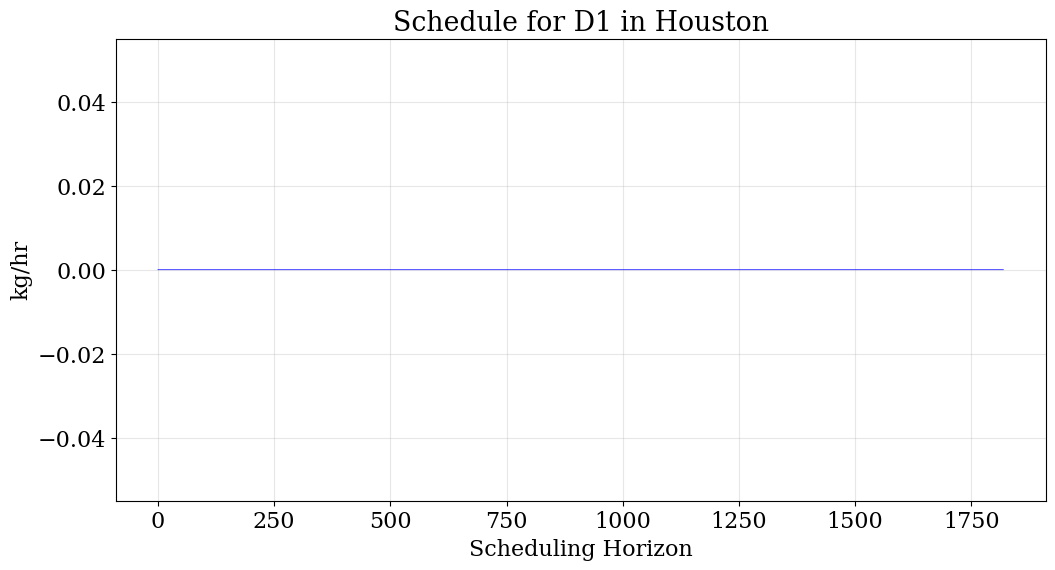

In [44]:
plot_results.schedule(results = results_cost, y_axis= 'P', component = 'D1', location='Houston')

In [45]:
# from energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
# from pyomo.environ import Var, Binary

# def modeler(gwp_pct: float):
#     gwp_eval = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
#                         Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'geq')
#     gwp_eval.cons2 = ConstraintList()
#     gwp_eval.cons3 = ConstraintList()
#     gwp_eval.cons4 = ConstraintList()
#     gwp_eval.cons5 = ConstraintList()
#     gwp_eval.cons8 = ConstraintList()
#     gwp_eval.cons9 = ConstraintList()
#     gwp_eval.cons10 = ConstraintList()
#     gwp_eval.cons11 = ConstraintList()
#     gwp_eval.cons13 = ConstraintList()
#     gwp_eval.cons14 = ConstraintList()
#     gwp_eval.cons15 = ConstraintList()
#     gwp_eval.cons17 = ConstraintList()

#     for i in scales.scale_iter(1):
#         gwp_eval.cons10.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] >= 0.35*gwp_eval.Cap_P['Houston','Conventional_NG', i[0]]) #30% of max production rate 6000 * milp_cost.on_smr[i]
#         gwp_eval.cons11.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] >= 0.35*gwp_eval.Cap_P['Houston','ShaleGas', i[0]]) #20% of max production rate
#         gwp_eval.cons13.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] >= 0.35*gwp_eval.Cap_P['Houston','Coalbed', i[0]]) #20% of max production rate
#         gwp_eval.cons14.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] <=gwp_eval.Cap_P['Houston','Conventional_NG', i[0]])
#         gwp_eval.cons15.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] <= gwp_eval.Cap_P['Houston','ShaleGas', i[0]])
#         gwp_eval.cons17.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] <= gwp_eval.Cap_P['Houston','Coalbed', i[0]])
#     if i != (0,0):
#             gwp_eval.cons2.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] - gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.1* gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
#             gwp_eval.cons3.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - gwp_eval.P['Houston', 'Conventional_NG', *i] <= 0.1*gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
#             gwp_eval.cons4.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] - gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.2* gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
#             gwp_eval.cons5.add(expr = gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - gwp_eval.P['Houston', 'ShaleGas', *i] <= 0.2*gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
#             gwp_eval.cons8.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] - gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.15* gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
#             gwp_eval.cons9.add(expr = gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - gwp_eval.P['Houston', 'Coalbed', *i] <= 0.15*gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
 
#     constraint_global_warming_potential_network_reduction(instance= gwp_eval, network_scale_level = 0, gwp_reduction_pct = gwp_pct, gwp = results_cost.output['global_warming_potential_network'][0])
    
#     return gwp_eval

from energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
from pyomo.environ import Var, Binary

def modeler(gwp_pct: float):
    gwp_eval = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                        Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'geq')
    gwp_eval.cons2 = ConstraintList()
    gwp_eval.cons3 = ConstraintList()
    gwp_eval.cons4 = ConstraintList()
    gwp_eval.cons5 = ConstraintList()
    gwp_eval.cons8 = ConstraintList()
    gwp_eval.cons9 = ConstraintList()
    gwp_eval.cons10 = ConstraintList()
    gwp_eval.cons11 = ConstraintList()
    gwp_eval.cons13 = ConstraintList()
    gwp_eval.cons14 = ConstraintList()
    gwp_eval.cons15 = ConstraintList()
    gwp_eval.cons17 = ConstraintList()

    for i in scales.scale_iter(2):
        gwp_eval.cons10.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] >= 0.5*gwp_eval.Cap_P['Houston','Conventional_NG', i[0]]) #30% of max production rate 6000 * milp_cost.on_smr[i]
        gwp_eval.cons11.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] >= 0.35*gwp_eval.Cap_P['Houston','ShaleGas', i[0]]) #20% of max production rate
        gwp_eval.cons13.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] >= 0.35*gwp_eval.Cap_P['Houston','Coalbed', i[0]]) #20% of max production rate
        # gwp_eval.cons14.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] <=gwp_eval.Cap_P['Houston','Conventional_NG', i[0]])
        # gwp_eval.cons15.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] <= gwp_eval.Cap_P['Houston','ShaleGas', i[0]])
        # gwp_eval.cons17.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] <= gwp_eval.Cap_P['Houston','Coalbed', i[0]])
    if i != (0,0,0):
            gwp_eval.cons2.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] - gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
            gwp_eval.cons3.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'Conventional_NG', *i] <= 0.10*gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
            gwp_eval.cons4.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] - gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
            gwp_eval.cons5.add(expr = gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'ShaleGas', *i] <= 0.2*gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
            gwp_eval.cons8.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] - gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
            gwp_eval.cons9.add(expr = gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'Coalbed', *i] <= 0.15*gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
 
    constraint_global_warming_potential_network_reduction(instance= gwp_eval, network_scale_level = 0, gwp_reduction_pct = gwp_pct, gwp = results_cost.output['global_warming_potential_network'][0])
    
    return gwp_eval

In [46]:
models = [modeler((i+1)*5) for i in range(20)]

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost
constraint global warming potential network reduction
constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost locatio

In [47]:
import os

# Create the 'res_red' directory if it doesn't exist
os.makedirs('res_red', exist_ok=True)

def solver(instance, i): 
    return solve(
        scenario=scenario, 
        instance=instance,
        solver='gurobi', 
        name=f"res_red/res_red_{i}", 
        print_solversteps=True, 
        saveformat='.pkl'
    )

# Assuming 'models' is a list of instances to be solved
results = {i: solver(m, i) for i, m in enumerate(models)}

Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 199296 rows, 1131306 columns and 674958 nonzeros
Model fingerprint: 0x2129b614
Variable types: 1131251 continuous, 55 integer (55 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 162815 rows and 1105741 columns
Presolve time: 0.11s
Presolved: 36481 rows, 25565 columns, 129343 nonzeros
Variable types: 25510 continuous, 55 integer (25 binary)
Performing another presolve...
Presolve removed 25658 rows and 20033 columns
Presolve time: 0.08s
Found heuristic solution: objective 3.683289e+07

Roo

In [48]:
for i in range(len(models)):
    print(results[i].output['termination'])

optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible


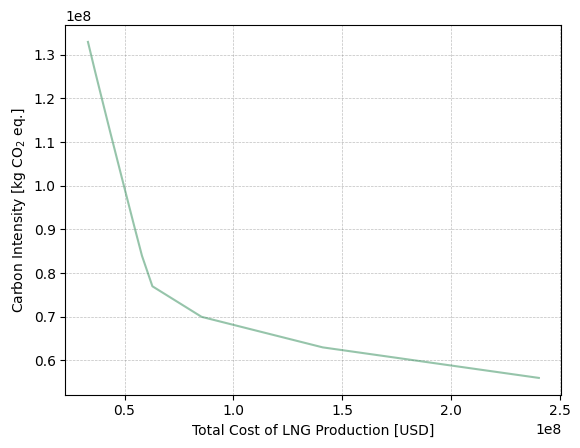

In [52]:
# cost = [None for i in range(len(results))]
# gwp_study = [None for i in range(len(results))]
# #gwpm_study = [None for i in range(len(results))]
# prod_study = [None for i in range(len(results))]


# for gwp_red, result in results.items():

#     if result.output['termination'] == 'optimal':
#         cost[gwp_red] = result.output['objective']
#         gwp_study[gwp_red] = result.output['global_warming_potential_location']['Houston',0]
#         #gwpm_study[gwp_red] = result.output['global_warming_potential_material'] ['Houston',0]
#         prod_study[gwp_red] = result.output['P']

# #print(type(gwp_study[0]))

# plt.plot(cost, gwp_study, color='seagreen', alpha=0.5)
# #, linestyle='--'
# plt.xlabel('Total Cost of LNG Production [USD]')
# plt.ylabel('Carbon Intensity [kg CO$_2$ eq.]')
# plt.ticklabel_format(style='sci', axis='x')  # For x-axis , scilimits=(0, 0)
# plt.ticklabel_format(style='sci', axis='y')  # For y-axis  , scilimits=(0, 0)
# plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha = 0.5)
# # Mark elbow points (use either elbow_indices or elbow_point)


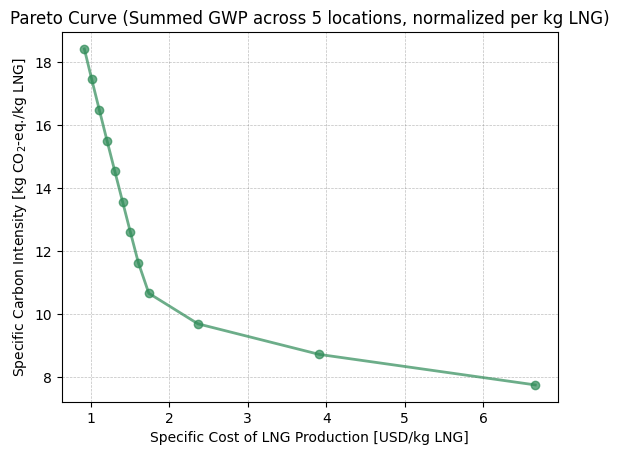

In [72]:
import numpy as np
import matplotlib.pyplot as plt

total_LNG_produced = 36078038  # total LNG produced in kg

cost = [None for _ in range(len(results))]
gwp_study = [None for _ in range(len(results))]
prod_study = [None for _ in range(len(results))]

for gwp_red, result in results.items():
    if result.output['termination'] == 'optimal':
        cost[gwp_red] = result.output['objective']

        # --- Sum over all 5 GWP location values ---
        total_gwp = 0
        for loc_index in range(5):  # assuming 5 time steps or location indices
            total_gwp += result.output['global_warming_potential_location']['Houston', loc_index]

        # --- Normalize total GWP by total LNG produced ---
        gwp_study[gwp_red] = total_gwp / total_LNG_produced

        # Keep production info (optional)
        prod_study[gwp_red] = result.output['P']

# --- Clean up None entries ---
mask = [c is not None and g is not None for c, g in zip(cost, gwp_study)]
cost = np.array([c for c, m in zip(cost, mask) if m]) / total_LNG_produced  # normalize cost too
gwp_study = np.array([g for g, m in zip(gwp_study, mask) if m])

# --- Plot normalized Pareto ---
plt.plot(cost, gwp_study, color='seagreen', alpha=0.7, linewidth=2, marker='o')
plt.xlabel('Specific Cost of LNG Production [USD/kg LNG]')
plt.ylabel('Specific Carbon Intensity [kg CO$_2$-eq./kg LNG]')
plt.ticklabel_format(style='sci', axis='x')
plt.ticklabel_format(style='sci', axis='y')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.title('Pareto Curve (Summed GWP across 5 locations, normalized per kg LNG)')
plt.show()


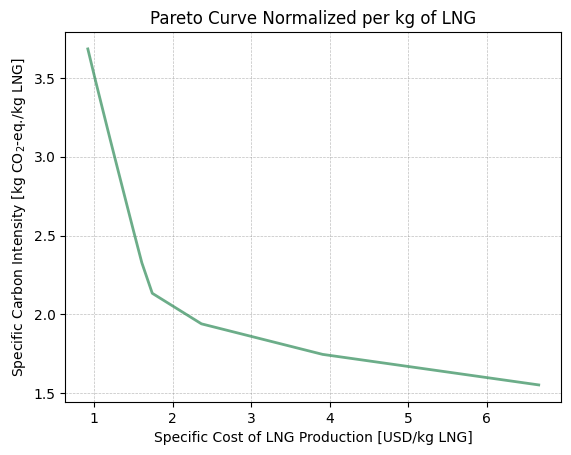

In [70]:
# total_LNG_produced = 36078038 # total in kg

# cost = [None for i in range(len(results))]
# gwp_study = [None for i in range(len(results))]
# prod_study = [None for i in range(len(results))]

# for gwp_red, result in results.items():
#     if result.output['termination'] == 'optimal':
#         cost[gwp_red] = result.output['objective']
#         gwp_study[gwp_red] = result.output['global_warming_potential_location']['Houston', 0]
#         prod_study[gwp_red] = result.output['P']

# # --- Normalize by total LNG production ---
# cost = [c / total_LNG_produced if c is not None else None for c in cost]
# gwp_study = [g / total_LNG_produced if g is not None else None for g in gwp_study]

# # Optionally remove None values (for cleaner plotting)
# import numpy as np
# mask = [c is not None and g is not None for c, g in zip(cost, gwp_study)]
# cost = np.array([c for c, m in zip(cost, mask) if m])
# gwp_study = np.array([g for g, m in zip(gwp_study, mask) if m])

# # --- Plot normalized Pareto ---
# plt.plot(cost, gwp_study, color='seagreen', alpha=0.7, linewidth=2)
# plt.xlabel('Specific Cost of LNG Production [USD/kg LNG]')
# plt.ylabel('Specific Carbon Intensity [kg CO$_2$-eq./kg LNG]')
# plt.ticklabel_format(style='sci', axis='x')
# plt.ticklabel_format(style='sci', axis='y')
# plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.title('Pareto Curve Normalized per kg of LNG')
# plt.show()


In [73]:
import numpy as np

np.save('pareto1_cost.npy', cost)
np.save('pareto1_gwp.npy', gwp_study)


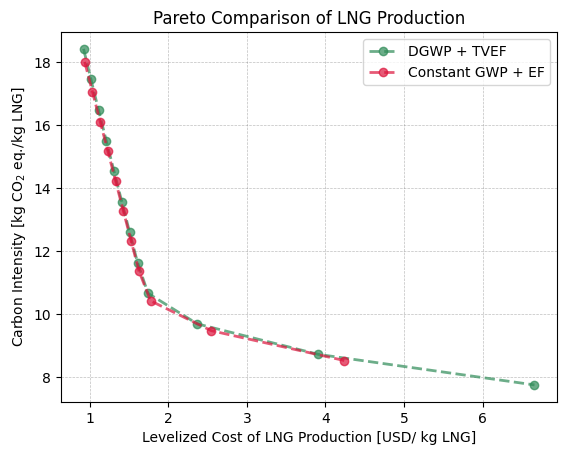

In [81]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Load data with pickle allowed
# cost1 = np.load('pareto1_cost.npy', allow_pickle=True)
# gwp1 = np.load('pareto1_gwp.npy', allow_pickle=True)

# cost2 = np.load('pareto2_cost.npy', allow_pickle=True)
# gwp2 = np.load('pareto2_gwp.npy', allow_pickle=True)

# # Plot
# plt.plot(cost1, gwp1, color='seagreen', label='DGWP + TVEF', alpha=0.7, linewidth=2, marker="o", linestyle="--")
# plt.plot(cost2, gwp2, color='crimson', label='Constant GWP + EF', alpha=0.7, linewidth=2, marker="o", linestyle="--")

# plt.xlabel('Levelized Cost of LNG Production [USD/ kg LNG]')
# plt.ylabel('Carbon Intensity [kg CO$_2$ eq./kg LNG]')
# plt.ticklabel_format(style='sci', axis='x')
# plt.ticklabel_format(style='sci', axis='y')
# plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.legend()
# plt.title('Pareto Comparison of LNG Production')
# plt.show()


In [ ]:
# from datetime import datetime, timedelta
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates

# # Generate time labels for 4 years, each with 365 days
# time_labels = [
#     datetime(2025, 1, 1) + timedelta(days=365 * k + j)
#     for k in range(0, 4)
#     for j in range(0, 365)
# ]

# # Example plots
# plt.plot(
#     time_labels,
#     [prod_study[30]['Houston', 'Conventional_NG', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="Conventional LNG"
# )
# plt.plot(
#     time_labels,
#     [prod_study[30]['Houston', 'ShaleGas', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="ShaleGas"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D1', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D1"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D2', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D2"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D3', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D3"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D4', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D4"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D5', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D5"
# )
# plt.plot(
#     time_labels,
#     [prod_study[10]['Houston', 'D6', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D6"
# )
# plt.xlabel('Time')
# plt.ylabel('Daily LNG Production [kg/day]')
# plt.ticklabel_format(style='sci', axis='y')
# plt.ylim(bottom=0)
# plt.xlim([time_labels[0], time_labels[-1]])

# plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# plt.legend()
# plt.show()


In [ ]:
# data = results_cost.output['P']
# df = pd.DataFrame(data,index=[0])
# df = df.T
# # Export the DataFrame to an Excel file
# df.to_excel(r'C:\Users\saatvisuresh_1\Desktop\Saatvi Thesis\5 year_final\P_output_F_both_Cost_min.xlsx', index=True)

In [98]:
#, Constraints.MODE

milp_gwp = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.MIN_GWP, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
constraint network cost
objective gwp min


In [99]:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate   *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]
# *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]

milp_gwp.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons1.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *i] - milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* milp_gwp.Cap_P['Houston', 'Conventional_NG',  i[0]])

#Constraint 2: Ramp down

milp_gwp.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons2.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Conventional_NG', *i] <= 0.10*milp_gwp.Cap_P['Houston', 'Conventional_NG',  i[0]])


# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons3.add(expr = milp_gwp.P['Houston', 'ShaleGas', *i] - milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* milp_gwp.Cap_P['Houston', 'ShaleGas', i[0]])

#Constraint 2: Ramp down

milp_gwp.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons4.add(expr = milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'ShaleGas', *i] <= 0.2*milp_gwp.Cap_P['Houston', 'ShaleGas', i[0]])

# Loop of how this code runsmilp_gwp
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons5.add(expr = milp_gwp.P['Houston', 'Coalbed', *i] - milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* milp_gwp.Cap_P['Houston', 'Coalbed', i[0]])

#Constraint 2: Ramp down

milp_gwp.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons6.add(expr = milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Coalbed', *i] <= 0.15*milp_gwp.Cap_P['Houston', 'Coalbed', i[0]])


milp_gwp.cons7 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons7.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *i] >= 0.5*milp_gwp.Cap_P['Houston','Conventional_NG', i[0]])

#0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

milp_gwp.cons8 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons8.add(expr = milp_gwp.P['Houston', 'ShaleGas', *i] >= 0.35*milp_gwp.Cap_P['Houston','ShaleGas', i[0]])

#0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

milp_gwp.cons9 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons9.add(expr = milp_gwp.P['Houston', 'Coalbed', *i] >= 0.35*milp_gwp.Cap_P['Houston','Coalbed', i[0]])

# 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]]

In [100]:
results_gwp = solve(scenario=scenario, instance=milp_gwp,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 210200 rows, 1131306 columns and 707763 nonzeros
Model fingerprint: 0x4e44ca0d
Variable types: 1131251 continuous, 55 integer (55 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 168276 rows and 1109386 columns
Presolve time: 0.13s
Presolved: 41924 rows, 21920 columns, 118382 nonzeros
Variable types: 21865 continuous, 55 integer (25 binary)
Performing another presolve...
Presolve removed 20040 rows and 16411 columns
Presolve time: 0.84s

Root relaxation: objective 2.780223e+08, 3377 iterat

In [101]:
results_gwp.output['global_warming_potential_location']

{('Houston', 0): 55604462.844395325,
 ('Houston', 1): 55604462.844395325,
 ('Houston', 2): 55604462.844395325,
 ('Houston', 3): 55604462.844395325,
 ('Houston', 4): 55604462.844395325}

In [104]:
55604462.844395325*4/36078038

6.164909837324893

In [102]:
results_gwp.output['Cost']

{None: 249262237.17292732}

In [105]:
249262237.17292732/36078038

6.908974295468266

In [103]:
results_gwp.output['X_P']

{('Houston', 'Coalbed', 0): -0.0,
 ('Houston', 'Coalbed', 1): -0.0,
 ('Houston', 'Coalbed', 2): -0.0,
 ('Houston', 'Coalbed', 3): -0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): 1.0,
 ('Houston', 'Conventional_NG', 1): 1.0,
 ('Houston', 'Conventional_NG', 2): 1.0,
 ('Houston', 'Conventional_NG', 3): 1.0,
 ('Houston', 'Conventional_NG', 4): 1.0,
 ('Houston', 'D1', 0): 1.0,
 ('Houston', 'D1', 1): 1.0,
 ('Houston', 'D1', 2): 1.0,
 ('Houston', 'D1', 3): 1.0,
 ('Houston', 'D1', 4): 1.0,
 ('Houston', 'D2', 0): 1.0,
 ('Houston', 'D2', 1): 1.0,
 ('Houston', 'D2', 2): 1.0,
 ('Houston', 'D2', 3): 1.0,
 ('Houston', 'D2', 4): 1.0,
 ('Houston', 'D3', 0): 1.0,
 ('Houston', 'D3', 1): 1.0,
 ('Houston', 'D3', 2): 1.0,
 ('Houston', 'D3', 3): 1.0,
 ('Houston', 'D3', 4): 1.0,
 ('Houston', 'D4', 0): 1.0,
 ('Houston', 'D4', 1): 1.0,
 ('Houston', 'D4', 2): 1.0,
 ('Houston', 'D4', 3): 1.0,
 ('Houston', 'D4', 4): 1.0,
 ('Houston', 'D5', 0): 1.0,
 ('Houston', 'D5', 1): 1.0,
 ('Houston